In [1]:
import numpy as np 
import pandas as pd
import seaborn as sns

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))


import kagglehub

/kaggle/input/competitions/titanic/train.csv
/kaggle/input/competitions/titanic/test.csv
/kaggle/input/competitions/titanic/gender_submission.csv


In [2]:
train_data = pd.read_csv("/kaggle/input/competitions/titanic/train.csv")
train_data.head(1)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.25,NaN,S


In [3]:
test_data = pd.read_csv("/kaggle/input/competitions/titanic/test.csv")
test_data.head(1)

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q


# Описание данных

In [4]:
print(train_data.info())
print()
print(train_data.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB
None

       PassengerId    Survived      Pclass         Age       SibSp  \
count   891.000000  891.000000  891.000000  714.000000  891.000000   
mean    446.000000    0.383838    2.308642   29.699118    0.523008   
std     257.353842    0.4865

# EDA

In [5]:
women = train_data.loc[train_data.Sex == 'female']["Survived"]
rate_women = sum(women)/len(women)

print("% of women who survived:", rate_women)

men = train_data.loc[train_data.Sex == 'male']["Survived"]
rate_men = sum(men)/len(men)

print("% of men who survived:", rate_men)

old = train_data.loc[train_data.Age >= 28]["Survived"]
rate_old = sum(old)/len(old)

print("% of people older then 50% who survived:", rate_old)

young = train_data.loc[train_data.Age < 28]["Survived"]
rate_young = sum(young)/len(young)

print("% of people younger then 50% who survived:", rate_young)

first = train_data.loc[train_data.Pclass == 1]["Survived"]
rate_first = sum(first)/len(first)

print("% of first class who survived:", rate_first)

second = train_data.loc[train_data.Pclass == 2]["Survived"]
rate_second = sum(second)/len(second)

print("% of second class who survived:", rate_second)

third = train_data.loc[train_data.Pclass == 3]["Survived"]
rate_third = sum(third)/len(third)

print("% of third class who survived:", rate_third)

% of women who survived: 0.7420382165605095
% of men who survived: 0.18890814558058924
% of people older then 50% who survived: 0.3952254641909814
% of people younger then 50% who survived: 0.41839762611275966
% of first class who survived: 0.6296296296296297
% of second class who survived: 0.47282608695652173
% of third class who survived: 0.24236252545824846


In [6]:
rich = train_data.loc[train_data.Pclass < 3]["Survived"]
rate_rich = sum(rich)/len(rich)

print("% of second and first class who survived:", rate_rich)

% of second and first class who survived: 0.5575


In [7]:
underage = train_data.loc[train_data.Age <= 18]["Survived"]
rate_underage = sum(underage)/len(underage)

print("% of underage who survived:", rate_underage)

% of underage who survived: 0.5035971223021583


In [8]:
age_nan = train_data.loc[train_data.Age.isna()]["Survived"]
rate_age_nan = sum(age_nan)/len(age_nan)

print("% of people without age data who survived:", rate_age_nan)

% of people without age data who survived: 0.2937853107344633


In [9]:
embarked_nan = train_data.loc[train_data.Embarked.isna()]["Survived"]
rate_embarked_nan = sum(embarked_nan)/len(embarked_nan)

print("% of people without embarked data who survived:", rate_embarked_nan)

% of people without embarked data who survived: 1.0


In [10]:
cabin_nan = train_data.loc[train_data.Cabin.isna()]["Survived"]
rate_cabin_nan = sum(cabin_nan)/len(cabin_nan)

print("% of people without cabin data who survived:", rate_cabin_nan)

% of people without cabin data who survived: 0.29985443959243085


In [11]:
age_approx = train_data.loc[train_data.Age % 1 == 0.5]["Survived"]
rate_age_approx = sum(age_approx)/len(age_approx)

print("% of people without accurate age data who survived:", rate_age_approx)
print("people without accurate age data:", len(age_approx))

% of people without accurate age data who survived: 0.05555555555555555
people without accurate age data: 18


In [12]:
train_data['Title'] = train_data['Name'].str.extract(r' ([A-Za-z]+)\.', expand=False)
print(train_data['Title'].value_counts())

Title
Mr          517
Miss        182
Mrs         125
Master       40
Dr            7
Rev           6
Col           2
Mlle          2
Major         2
Ms            1
Mme           1
Don           1
Lady          1
Sir           1
Capt          1
Countess      1
Jonkheer      1
Name: count, dtype: int64


Есть основные 4 титула(Mr, Mrs, Miss, Master и их аналоги), остальные достаточно редки, будем считать их 'Остальными'.

In [13]:
train_data['Title'] = train_data['Title'].replace({'Mlle': 'Miss', 'Ms': 'Miss', 'Mme': 'Mrs'})

main_titles = ['Mr', 'Mrs', 'Miss', 'Master']
train_data['Title'] = train_data['Title'].apply(lambda x: x if x in main_titles else 'Other')

print(train_data['Title'].value_counts())

Title
Mr        517
Miss      185
Mrs       126
Master     40
Other      23
Name: count, dtype: int64


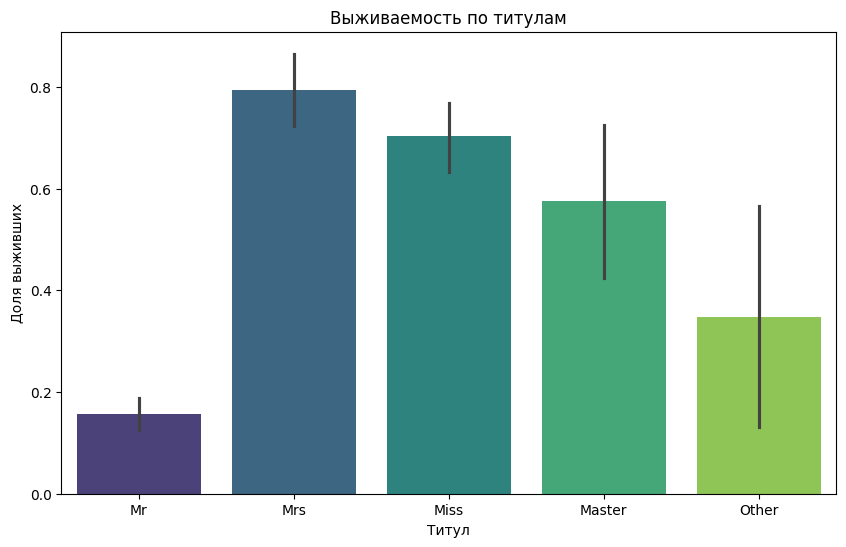

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.barplot(x='Title', y='Survived', data=train_data, 
            palette='viridis', hue='Title', legend=False)

plt.title('Выживаемость по титулам')
plt.ylabel('Доля выживших')
plt.xlabel('Титул')
plt.show()

In [15]:
train_data['FamilySize'] = train_data['SibSp'] + train_data['Parch'] + 1

train_data['IsAlone'] = (train_data['FamilySize'] == 1).astype(int)

print(train_data['FamilySize'].value_counts())

FamilySize
1     537
2     161
3     102
4      29
6      22
5      15
7      12
11      7
8       6
Name: count, dtype: int64


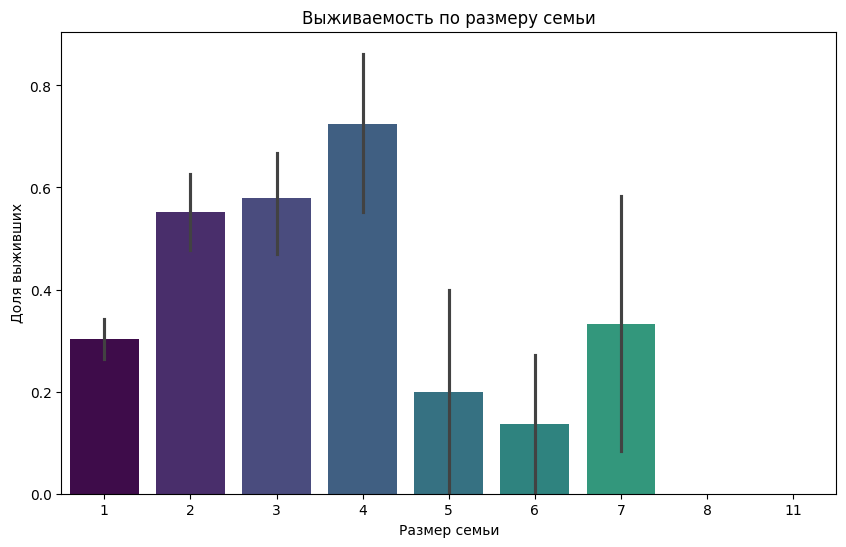

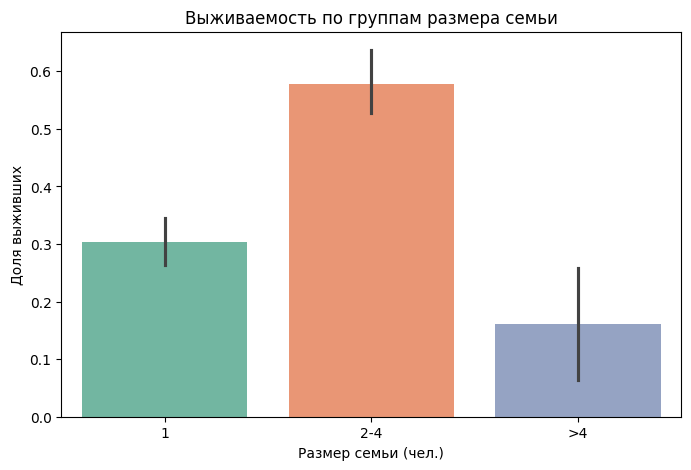

In [16]:
plt.figure(figsize=(10, 6))

sns.barplot(x='FamilySize', y='Survived', data=train_data, 
            palette='viridis', hue='FamilySize', legend=False)

plt.title('Выживаемость по размеру семьи')
plt.ylabel('Доля выживших')
plt.xlabel('Размер семьи')
plt.show()

train_data['FamilyGroup'] = pd.cut(
    train_data['FamilySize'], 
    bins=[0, 1, 4, 12], 
    labels=['1', '2-4', '>4']
)

plt.figure(figsize=(8, 5))

sns.barplot(x='FamilyGroup', y='Survived', data=train_data, 
            palette='Set2', hue='FamilyGroup', legend=False)

plt.title('Выживаемость по группам размера семьи')
plt.ylabel('Доля выживших')
plt.xlabel('Размер семьи (чел.)')
plt.show()

train_data = train_data.drop(columns = ['FamilyGroup'])

### Вывод

Женщины выживали сильно чаще мужчин. Первый класс выживал чаще всех остальных, третий класс выживал в два раза реже, чем богатые(1-2 класс). Взрослые женщины выживали чуть чаще молодых, мальчики(Master) выживали сильно чаще взрослых мужчин. Маленькие семьи выживали чаще людей, плывущих в одиночку. Большие семьи выживали сильно реже.

# Работа с признаками

In [17]:
print("unique sexes: ", train_data['Sex'].nunique())
print("unique ticket numbers: ", train_data['Ticket'].nunique())
print("unique cabin numbers: ", train_data['Cabin'].nunique())
print("unique embarked: ", train_data['Embarked'].nunique())

unique sexes:  2
unique ticket numbers:  681
unique cabin numbers:  147
unique embarked:  3


In [18]:
mode_value = train_data['Embarked'].mode()[0]
train_data['Embarked'] = train_data['Embarked'].fillna(mode_value)
print(train_data['Embarked'].isnull().sum()) 
print(mode_value)

0
S


In [19]:
train_data = train_data.drop(columns = ['Name', 'Cabin', 'Ticket'])

train_data = pd.get_dummies(train_data, prefix=None, prefix_sep='_', dummy_na=False,
               columns=None, drop_first=True, dtype=None)

print(train_data.shape[1])
print(train_data.info())

16
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 16 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Age          714 non-null    float64
 4   SibSp        891 non-null    int64  
 5   Parch        891 non-null    int64  
 6   Fare         891 non-null    float64
 7   FamilySize   891 non-null    int64  
 8   IsAlone      891 non-null    int64  
 9   Sex_male     891 non-null    bool   
 10  Embarked_Q   891 non-null    bool   
 11  Embarked_S   891 non-null    bool   
 12  Title_Miss   891 non-null    bool   
 13  Title_Mr     891 non-null    bool   
 14  Title_Mrs    891 non-null    bool   
 15  Title_Other  891 non-null    bool   
dtypes: bool(7), float64(2), int64(7)
memory usage: 68.9 KB
None


<Axes: >

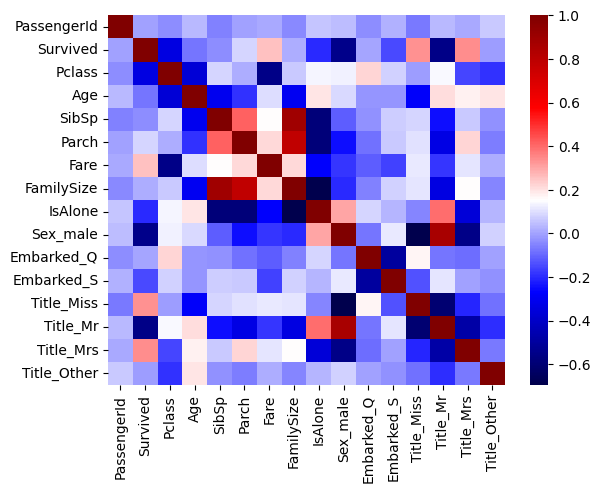

In [20]:
sns.heatmap(train_data.corr(), cmap='seismic')

Умеренная связь есть у Fare и Pclass(дороже билет -> меньше класс(логично)), Sex_male и Survived(мужчины -> не выживают(80%)), SibSp и Parch(больше сиблингов/супругов -> больше родителей/детей(плыли семьями)). Есть большая связь между титулом и полом(например, обратная связь между титулом Miss и мужским полом, у Mrs связь чуть меньше, вероятно, потому что их меньше). Есть связи между признаками, связанными с семьей.

In [21]:
train_data = train_data.drop(columns = ['PassengerId'])

# Работа с пропусками в Age

### 0) Ничего не делать(оставить NaN)

### 1) Заполнить пропуски медианой

In [22]:
med_value = train_data['Age'].median()
train_data_1 = train_data.copy()
train_data_1['Age'] = train_data_1['Age'].fillna(med_value)
print(train_data_1['Age'].isnull().sum())
print(med_value)

0
28.0


### 2) Заполнить пропуски медианой + добавить колонку Age_Missing 

In [23]:
med_value = train_data['Age'].median()
train_data_2 = train_data.copy()
train_data_2['Age_Missing'] = train_data_2['Age'].isnull().astype(bool)
train_data_2['Age'] = train_data_2['Age'].fillna(med_value)
print(train_data_2['Age'].isnull().sum())
print(train_data_2['Age_Missing'].sum()) 
print(med_value)

0
177
28.0


### 3) Заполнить пропуски Sentinel value(-999)

In [24]:
train_data_3 = train_data.copy()
train_data_3['Age'] = train_data_3['Age'].fillna(-999)
print(train_data_3['Age'].isnull().sum())
print(med_value)

0
28.0


### 4) Биннинг + добавление свойства missing

In [25]:
train_data_4 = train_data.copy()

train_data_4['Age_bin'] = pd.cut(
    train_data_4['Age'],
    bins=[0, 12, 18, 30, 50, 80],
    labels=['child', 'teen', 'young', 'adult', 'senior']
)

train_data_4['Age_bin'] = train_data_4['Age_bin'].cat.add_categories('missing')
train_data_4['Age_bin'] = train_data_4['Age_bin'].fillna('missing')

train_data_4 = pd.get_dummies(train_data_4, columns=['Age_bin'], drop_first=True, dtype=int)
train_data_4 = train_data_4.drop(columns=['Age'])
print(train_data_4.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 19 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Survived         891 non-null    int64  
 1   Pclass           891 non-null    int64  
 2   SibSp            891 non-null    int64  
 3   Parch            891 non-null    int64  
 4   Fare             891 non-null    float64
 5   FamilySize       891 non-null    int64  
 6   IsAlone          891 non-null    int64  
 7   Sex_male         891 non-null    bool   
 8   Embarked_Q       891 non-null    bool   
 9   Embarked_S       891 non-null    bool   
 10  Title_Miss       891 non-null    bool   
 11  Title_Mr         891 non-null    bool   
 12  Title_Mrs        891 non-null    bool   
 13  Title_Other      891 non-null    bool   
 14  Age_bin_teen     891 non-null    int64  
 15  Age_bin_young    891 non-null    int64  
 16  Age_bin_adult    891 non-null    int64  
 17  Age_bin_senior  

# Оценка моделей

Для оценки моделей будем использовать Cross-validation(K-fold), чтобы не было утечек будет использовать train_data(с пропусками в Age) и пропуски заполнять по ходу CV.

In [26]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_validate

In [27]:
y = train_data['Survived']
X = train_data.drop(columns=['Survived'])

### 1) Логистическая регрессия

In [28]:
from sklearn.linear_model import LogisticRegression
continuous_features = ['Age', 'Pclass', 'SibSp', 'FamilySize', 'Parch', 'Fare']
passthrough_features = [c for c in X.columns if c not in continuous_features]

preprocessor = ColumnTransformer([
    ('cont', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]), continuous_features),
    ('rest', 'passthrough', passthrough_features)
])

pipe_lr = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(C=1.0, solver='lbfgs', max_iter=1000, random_state=42))
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {'accuracy': 'accuracy', 'f1': 'f1', 'roc_auc': 'roc_auc',
           'precision': 'precision', 'recall': 'recall'}

cv_results = cross_validate(pipe_lr, X, y, cv=cv, scoring=scoring,
                            n_jobs=-1, return_train_score=True)

for metric in ['accuracy', 'f1', 'roc_auc', 'precision', 'recall']:
    scores = cv_results[f'test_{metric}']
    print(f"{metric:10s}: {scores.mean():.4f} ± {scores.std():.4f}  |  по фолдам: {scores.round(4)}")

print()
print(f"Train accuracy: {cv_results['train_accuracy'].mean():.4f}")
print(f"Val accuracy:   {cv_results['test_accuracy'].mean():.4f}")
print(f"Разрыв:         {cv_results['train_accuracy'].mean() - cv_results['test_accuracy'].mean():.4f}")

accuracy  : 0.8204 ± 0.0062  |  по фолдам: [0.8212 0.809  0.8202 0.8258 0.8258]
f1        : 0.7593 ± 0.0136  |  по фолдам: [0.7714 0.7463 0.7419 0.7597 0.777 ]
roc_auc   : 0.8701 ± 0.0192  |  по фолдам: [0.8877 0.8694 0.8503 0.8475 0.8954]
precision : 0.7829 ± 0.0252  |  по фолдам: [0.7606 0.7576 0.8214 0.8033 0.7714]
recall    : 0.7395 ± 0.0402  |  по фолдам: [0.7826 0.7353 0.6765 0.7206 0.7826]

Train accuracy: 0.8280
Val accuracy:   0.8204
Разрыв:         0.0076


### 2) KNN

In [29]:
from sklearn.neighbors import KNeighborsClassifier

pipe_knn = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),   
    ('scaler', StandardScaler()),                    
    ('model', KNeighborsClassifier(
        n_neighbors=5,
        weights='uniform',       
        metric='minkowski',      
        p=2,
        n_jobs=-1
    ))
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {'accuracy': 'accuracy', 'f1': 'f1', 'roc_auc': 'roc_auc',
           'precision': 'precision', 'recall': 'recall'}

cv_results_knn = cross_validate(
    pipe_knn, X, y, cv=cv, scoring=scoring,
    n_jobs=-1, return_train_score=True
)

for metric in ['accuracy', 'f1', 'roc_auc', 'precision', 'recall']:
    scores = cv_results_knn[f'test_{metric}']
    print(f"{metric:10s}: {scores.mean():.4f} ± {scores.std():.4f}  |  по фолдам: {scores.round(4)}")

print()
print(f"Train accuracy: {cv_results_knn['train_accuracy'].mean():.4f}")
print(f"Val accuracy:   {cv_results_knn['test_accuracy'].mean():.4f}")
print(f"Разрыв:         {cv_results_knn['train_accuracy'].mean() - cv_results_knn['test_accuracy'].mean():.4f}")

accuracy  : 0.8260 ± 0.0211  |  по фолдам: [0.8324 0.8146 0.7921 0.8539 0.8371]
f1        : 0.7647 ± 0.0287  |  по фолдам: [0.7761 0.7556 0.7132 0.7937 0.7852]
roc_auc   : 0.8557 ± 0.0195  |  по фолдам: [0.8805 0.8475 0.823  0.8602 0.8671]
precision : 0.7961 ± 0.0385  |  по фолдам: [0.8    0.7612 0.7541 0.8621 0.803 ]
recall    : 0.7367 ± 0.0319  |  по фолдам: [0.7536 0.75   0.6765 0.7353 0.7681]

Train accuracy: 0.8650
Val accuracy:   0.8260
Разрыв:         0.0390


### 3) Случайный лес

In [30]:
from sklearn.ensemble import RandomForestClassifier

pipe_rf = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),   
    ('model', RandomForestClassifier(
        n_estimators=300,        
        max_depth=None,          
        min_samples_split=2,     
        min_samples_leaf=1,      
        max_features='sqrt',     
        bootstrap=True,          
        random_state=42,
        n_jobs=-1
    ))
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {'accuracy': 'accuracy', 'f1': 'f1', 'roc_auc': 'roc_auc',
           'precision': 'precision', 'recall': 'recall'}

cv_results_rf = cross_validate(
    pipe_rf, X, y, cv=cv, scoring=scoring,
    n_jobs=-1, return_train_score=True
)


for metric in ['accuracy', 'f1', 'roc_auc', 'precision', 'recall']:
    scores = cv_results_rf[f'test_{metric}']
    print(f"{metric:10s}: {scores.mean():.4f} ± {scores.std():.4f}  |  по фолдам: {scores.round(4)}")

print()
print(f"Train accuracy: {cv_results_rf['train_accuracy'].mean():.4f}")
print(f"Val accuracy:   {cv_results_rf['test_accuracy'].mean():.4f}")
print(f"Разрыв:         {cv_results_rf['train_accuracy'].mean() - cv_results_rf['test_accuracy'].mean():.4f}")

accuracy  : 0.8114 ± 0.0144  |  по фолдам: [0.8101 0.7978 0.7978 0.8146 0.8371]
f1        : 0.7536 ± 0.0190  |  по фолдам: [0.7463 0.7465 0.7313 0.7556 0.7883]
roc_auc   : 0.8693 ± 0.0255  |  по фолдам: [0.9057 0.8472 0.8441 0.8555 0.8939]
precision : 0.7566 ± 0.0262  |  по фолдам: [0.7692 0.7162 0.7424 0.7612 0.7941]
recall    : 0.7514 ± 0.0262  |  по фолдам: [0.7246 0.7794 0.7206 0.75   0.7826]

Train accuracy: 0.9834
Val accuracy:   0.8114
Разрыв:         0.1720


### 4) Градиентный бустинг

In [31]:
from sklearn.ensemble import HistGradientBoostingClassifier

pipe_hgb = Pipeline([
    ('model', HistGradientBoostingClassifier(
        max_iter=300,           
        learning_rate=0.05,     
        max_depth=None,         
        max_leaf_nodes=31,      
        min_samples_leaf=20,    
        l2_regularization=0.0,  
        early_stopping=True,    
        validation_fraction=0.1,
        n_iter_no_change=10,    
        random_state=42
    ))
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {'accuracy': 'accuracy', 'f1': 'f1', 'roc_auc': 'roc_auc',
           'precision': 'precision', 'recall': 'recall'}

cv_results_hgb = cross_validate(
    pipe_hgb, X, y, cv=cv, scoring=scoring,
    n_jobs=-1, return_train_score=True
)


for metric in ['accuracy', 'f1', 'roc_auc', 'precision', 'recall']:
    scores = cv_results_hgb[f'test_{metric}']
    print(f"{metric:10s}: {scores.mean():.4f} ± {scores.std():.4f}  |  по фолдам: {scores.round(4)}")

print()
print(f"Train accuracy: {cv_results_hgb['train_accuracy'].mean():.4f}")
print(f"Val accuracy:   {cv_results_hgb['test_accuracy'].mean():.4f}")
print(f"Разрыв:         {cv_results_hgb['train_accuracy'].mean() - cv_results_hgb['test_accuracy'].mean():.4f}")

accuracy  : 0.8249 ± 0.0097  |  по фолдам: [0.8268 0.8315 0.809  0.8371 0.8202]
f1        : 0.7591 ± 0.0152  |  по фолдам: [0.7634 0.7619 0.7302 0.7752 0.7647]
roc_auc   : 0.8751 ± 0.0202  |  по фолдам: [0.8914 0.8848 0.8387 0.8681 0.8924]
precision : 0.8046 ± 0.0185  |  по фолдам: [0.8065 0.8276 0.7931 0.8197 0.7761]
recall    : 0.7192 ± 0.0264  |  по фолдам: [0.7246 0.7059 0.6765 0.7353 0.7536]

Train accuracy: 0.8917
Val accuracy:   0.8249
Разрыв:         0.0668


### 5) SVC

In [32]:
from sklearn.svm import SVC

pipe_svc = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),   
    ('scaler', StandardScaler()),                    
    ('model', SVC(
        kernel='rbf',           
        C=1.0,                  
        gamma='scale',          
        probability=True,       
        random_state=42
    ))
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {'accuracy': 'accuracy', 'f1': 'f1', 'roc_auc': 'roc_auc',
           'precision': 'precision', 'recall': 'recall'}

cv_results_svc = cross_validate(
    pipe_svc, X, y, cv=cv, scoring=scoring,
    n_jobs=-1, return_train_score=True
)

for metric in ['accuracy', 'f1', 'roc_auc', 'precision', 'recall']:
    scores = cv_results_svc[f'test_{metric}']
    print(f"{metric:10s}: {scores.mean():.4f} ± {scores.std():.4f}  |  по фолдам: {scores.round(4)}")

print()
print(f"Train accuracy: {cv_results_svc['train_accuracy'].mean():.4f}")
print(f"Val accuracy:   {cv_results_svc['test_accuracy'].mean():.4f}")
print(f"Разрыв:         {cv_results_svc['train_accuracy'].mean() - cv_results_svc['test_accuracy'].mean():.4f}")

accuracy  : 0.8316 ± 0.0160  |  по фолдам: [0.838  0.8034 0.8258 0.8427 0.8483]
f1        : 0.7674 ± 0.0251  |  по фолдам: [0.782  0.7287 0.748  0.7812 0.797 ]
roc_auc   : 0.8511 ± 0.0245  |  по фолдам: [0.8695 0.8501 0.8043 0.87   0.8615]
precision : 0.8162 ± 0.0243  |  по фолдам: [0.8125 0.7705 0.8364 0.8333 0.8281]
recall    : 0.7249 ± 0.0354  |  по фолдам: [0.7536 0.6912 0.6765 0.7353 0.7681]

Train accuracy: 0.8454
Val accuracy:   0.8316
Разрыв:         0.0138


### Вывод

In [33]:
models_results = [
    {"Модель": "LogisticRegression", "CV": cv_results},
    {"Модель": "KNN (k=5)", "CV": cv_results_knn},
    {"Модель": "RandomForest", "CV": cv_results_rf},
    {"Модель": "HistGradientBoosting", "CV": cv_results_hgb},
    {"Модель": "SVC", "CV": cv_results_svc}
]

table_data = []

for item in models_results:
    name = item["Модель"]
    res = item["CV"]
    
    train_acc = res['train_accuracy'].mean()
    val_acc = res['test_accuracy'].mean()
    f1 = res['test_f1'].mean()
    roc_auc = res['test_roc_auc'].mean()
    
    gap = train_acc - val_acc
    
    table_data.append({
        "Модель": name,
        "CV Accuracy": round(val_acc, 4),
        "F1-Score": round(f1, 4),
        "ROC-AUC": round(roc_auc, 4),
        "Train Accuracy": round(train_acc, 4),
        "Разрыв": round(gap, 4)
    })

df_results = pd.DataFrame(table_data)
df_results = df_results.sort_values(by="CV Accuracy", ascending=False).reset_index(drop=True)

display(df_results.style.hide(axis='index').set_properties(**{'text-align': 'left'}))

best_model = df_results.iloc[0]
print(f"Лучшая модель по CV: {best_model['Модель']} (Accuracy: {best_model['CV Accuracy']})")

Модель,CV Accuracy,F1-Score,ROC-AUC,Train Accuracy,Разрыв
SVC,0.831600,0.767400,0.851100,0.845400,0.013800
KNN (k=5),0.826000,0.764700,0.855700,0.865000,0.039000
HistGradientBoosting,0.824900,0.759100,0.875100,0.891700,0.066800
LogisticRegression,0.820400,0.759300,0.870100,0.828000,0.007600
RandomForest,0.811400,0.753600,0.869300,0.983400,0.172000


Лучшая модель по CV: SVC (Accuracy: 0.8316)


# Permutation importance

In [34]:
from sklearn.inspection import permutation_importance

pipe_svc.fit(X, y)
perm = permutation_importance(
    pipe_svc, X, y, 
    n_repeats=10, 
    random_state=42, 
    n_jobs=-1, 
    scoring='accuracy'
)

perm_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance_Mean': perm.importances_mean,
    'Importance_Std': perm.importances_std
}).sort_values(by='Importance_Mean', ascending=False)

print(perm_df)

        Feature  Importance_Mean  Importance_Std
11     Title_Mr         0.153086        0.011557
2         SibSp         0.016274        0.003413
0        Pclass         0.015039        0.001824
13  Title_Other         0.011785        0.002420
3         Parch         0.008754        0.001489
9    Embarked_S         0.008754        0.002057
5    FamilySize         0.008081        0.001995
1           Age         0.006397        0.001742
4          Fare         0.005051        0.001757
8    Embarked_Q         0.004714        0.001571
10   Title_Miss         0.003591        0.001402
7      Sex_male         0.003479        0.002325
12    Title_Mrs         0.003143        0.001489
6       IsAlone         0.000337        0.002658


### Вывод

Самым влиятельным признаком является 'Title_Mr', что логично так как взрослые мужчины выживали очень редко(влиятельный признак), при этом 'Sex_male' неожиданно имел малое влияние, что можно объяснить наличием титулов(по которому можно определить пол). 
В целом, признаки не сильно влияли, так как для многих признаков есть какие-то частично дублирующие информацию.

# Логистическая регрессия

In [35]:
pipe_lr.fit(X, y)
coefs = pd.Series(
    pipe_lr.named_steps['model'].coef_[0],
    index=X.columns
).sort_values()

print(coefs)

Title_Mr      -2.414698
Title_Other   -1.708513
Age           -0.838762
Sex_male      -0.768809
IsAlone       -0.428852
Title_Miss    -0.395938
SibSp         -0.387600
Pclass        -0.385687
Embarked_S    -0.337785
Parch         -0.332582
Fare          -0.135454
Embarked_Q     0.010957
FamilySize     0.153487
Title_Mrs      0.230759
dtype: float64


### Вывод

Интерпретация модели:
1. **`Title_Mr` (-2.41)** — самый сильный отрицательный коэффициент. Модель вычислила, что Mr выживали реже всех(что и мы обнаружили ранее).
2. **`Title_Other` (-1.71)** — также сильно снижает шансы.
3. **`Title_Mrs` (+0.23)** — замужние женщины имеют положительный коэффициент, что логично (их спасали в первую очередь).
4. **`Sex_male` (-0.77)** — пол сохраняет свою важность даже при наличии признака `Title`, что говорит о том, что модель извлекла из них разную информацию.
5. **`Fare` (-0.13)** и **`Embarked` (~0.00)** — слабое влияние на предсказание в данной конфигурации.

**Вывод:** Знаки и величины коэффициентов полностью согласуются с EDA и историческим контекстом катастрофы, что подтверждает адекватность и отсутствие переобучения модели.

# Сравнение стратегий заполнения Age

In [36]:
for name, df in [('median', train_data_1),
                 ('median+flag', train_data_2),
                 ('sentinel -999', train_data_3),
                 ('binning', train_data_4)]:
    
    X_exp = X.copy() 
    
    if 'Age' in df.columns:
        X_exp['Age'] = df['Age']
    else:
        X_exp = X_exp.drop(columns=['Age'])
        bin_cols = [c for c in df.columns if 'Age_bin' in c]
        X_exp = pd.concat([X_exp, df[bin_cols]], axis=1)

    res = cross_validate(pipe_svc, X_exp, y, cv=cv,
                         scoring='accuracy', n_jobs=-1)
    print(f"{name:15s}: {res['test_score'].mean():.4f} ± {res['test_score'].std():.4f}")

median         : 0.8316 ± 0.0160
median+flag    : 0.8316 ± 0.0160
sentinel -999  : 0.8328 ± 0.0136
binning        : 0.8339 ± 0.0092


### Вывод

Лучший результат показала стратегия группировки(биннинга) признака и добавление свойства отсутствующего возраста. В дальнейшем будем ее использовать. Эта стратегия дала лучшее Accuracy, а так же оказалась наиболее стабильной(разброс меньше 1%).

# Генерация ответа

In [37]:
y = train_data_4['Survived']
X = train_data_4.drop(columns=['Survived'])

test_raw = test_data
test_ids = test_raw['PassengerId']

test_proc = test_raw.copy()

test_proc['Title'] = test_proc['Name'].str.extract(r' ([A-Za-z]+)\.', expand=False)
test_proc['Title'] = test_proc['Title'].replace({'Mlle': 'Miss', 'Ms': 'Miss', 'Mme': 'Mrs'})

main_titles = ['Mr', 'Mrs', 'Miss', 'Master']
test_proc['Title'] = test_proc['Title'].apply(lambda x: x if x in main_titles else 'Other')

test_proc = test_proc.drop(columns=['PassengerId', 'Name', 'Ticket', 'Cabin'])

fare_median = train_data['Fare'].median()
test_proc['Fare'] = test_proc['Fare'].fillna(fare_median)

embarked_mode = 'S'  
test_proc['Embarked'] = test_proc['Embarked'].fillna(embarked_mode)

test_proc['Age_bin'] = pd.cut(
    test_proc['Age'],
    bins=[0, 12, 18, 30, 50, 80],
    labels=['child', 'teen', 'young', 'adult', 'senior']
)

test_proc['Age_bin'] = test_proc['Age_bin'].cat.add_categories('missing')
test_proc['Age_bin'] = test_proc['Age_bin'].fillna('missing')

test_proc = test_proc.drop(columns=['Age'])

test_proc['FamilySize'] = test_proc['SibSp'] + test_proc['Parch'] + 1

test_proc['IsAlone'] = (test_proc['FamilySize'] == 1).astype(int)

test_proc = pd.get_dummies(
    test_proc,
    columns=['Sex', 'Embarked', 'Title', 'Age_bin'],
    drop_first=True,
    dtype=int
)
print("\nКолонки test ДО align:", test_proc.columns.tolist())
print("Fare в test — пропуски:", test_proc['Fare'].isnull().sum())   

X_train_aligned, X_test_aligned = X.align(
    test_proc, join='left', axis=1, fill_value=0
)

print("\nПосле align:")
print("X_train:", X_train_aligned.shape)
print("X_test: ", X_test_aligned.shape)
print("Колонки совпадают:", list(X_train_aligned.columns) == list(X_test_aligned.columns))
print("Колонки:", X_train_aligned.columns.tolist())

print("\nFare в X_test_aligned — статистика:")
print(X_test_aligned['Fare'].describe())

pipe_svc_final = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('model', SVC(
        kernel='rbf',
        C=1.0,
        gamma='scale',
        probability=False,
        random_state=42
    ))
])

pipe_svc_final.fit(X_train_aligned, y)

predictions = pipe_svc_final.predict(X_test_aligned)

submission = pd.DataFrame({
    'PassengerId': test_ids,
    'Survived': predictions
})

submission.to_csv('submission.csv', index=False)

print("\nДоля выживших в submission:", predictions.mean())

print("submission.csv сохранён")


Колонки test ДО align: ['Pclass', 'SibSp', 'Parch', 'Fare', 'FamilySize', 'IsAlone', 'Sex_male', 'Embarked_Q', 'Embarked_S', 'Title_Miss', 'Title_Mr', 'Title_Mrs', 'Title_Other', 'Age_bin_teen', 'Age_bin_young', 'Age_bin_adult', 'Age_bin_senior', 'Age_bin_missing']
Fare в test — пропуски: 0

После align:
X_train: (891, 18)
X_test:  (418, 18)
Колонки совпадают: True
Колонки: ['Pclass', 'SibSp', 'Parch', 'Fare', 'FamilySize', 'IsAlone', 'Sex_male', 'Embarked_Q', 'Embarked_S', 'Title_Miss', 'Title_Mr', 'Title_Mrs', 'Title_Other', 'Age_bin_teen', 'Age_bin_young', 'Age_bin_adult', 'Age_bin_senior', 'Age_bin_missing']

Fare в X_test_aligned — статистика:
count    418.000000
mean      35.576535
std       55.850103
min        0.000000
25%        7.895800
50%       14.454200
75%       31.471875
max      512.329200
Name: Fare, dtype: float64

Доля выживших в submission: 0.3875598086124402
submission.csv сохранён
